In [ ]:
# If needed, install dependencies:
# %pip install scikit-learn pandas numpy matplotlib joblib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Load data and create one fixed train/test split

In [3]:
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Full dataset:", X.shape)
print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Full dataset: (20640, 8)
Train rows: 16512
Test rows: 4128


## 2. Train a baseline Pipeline

In [4]:
baseline_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

baseline_pipeline.fit(X_train, y_train)
baseline_pred = baseline_pipeline.predict(X_test)

## 3. Tune the Pipeline with GridSearchCV

GridSearchCV tests the parameter combinations below using 3-fold cross-validation. It selects the best combination based on negative MAE (lower MAE is better).

In [5]:
param_grid = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [None, 20],
    "regressor__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=3,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)
best_pipeline = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 2, 'regressor__n_estimators': 200}
Best CV MAE: 0.3386167141174867


## 4. Evaluate baseline vs tuned model on the same test set

In [6]:
tuned_pred = best_pipeline.predict(X_test)

def regression_metrics(y_true, y_hat):
    return {
        "MAE": mean_absolute_error(y_true, y_hat),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
        "R2": r2_score(y_true, y_hat)
    }

comparison = pd.DataFrame(
    {
        "Baseline": regression_metrics(y_test, baseline_pred),
        "Tuned GridSearchCV": regression_metrics(y_test, tuned_pred)
    }
).T

display(comparison.round(4))

,MAE,RMSE,R2
Baseline,0.3274,0.5051,0.8053
Tuned GridSearchCV,0.3259,0.5038,0.8063


In [7]:
mae_improvement_pct = (
    (comparison.loc["Baseline", "MAE"] -
     comparison.loc["Tuned GridSearchCV", "MAE"]) /
    comparison.loc["Baseline", "MAE"] * 100
)
rmse_improvement_pct = (
    (comparison.loc["Baseline", "RMSE"] -
     comparison.loc["Tuned GridSearchCV", "RMSE"]) /
    comparison.loc["Baseline", "RMSE"] * 100
)
r2_change = (
    comparison.loc["Tuned GridSearchCV", "R2"] -
    comparison.loc["Baseline", "R2"]
)

print(f"MAE reduction: {mae_improvement_pct:.2f}%")
print(f"RMSE reduction: {rmse_improvement_pct:.2f}%")
print(f"R² change: {r2_change:+.4f}")
print("Positive MAE/RMSE reduction and positive R² change indicate improvement.")

MAE reduction: 0.46%
RMSE reduction: 0.27%
R² change: +0.0010
Positive MAE/RMSE reduction and positive R² change indicate improvement.


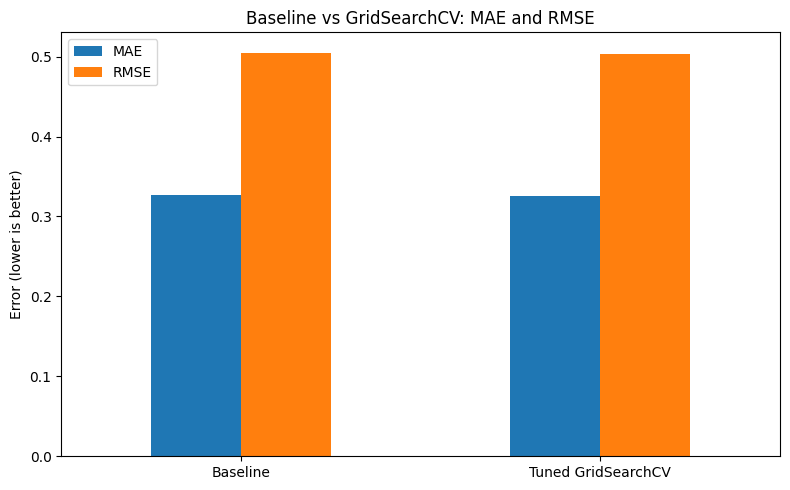

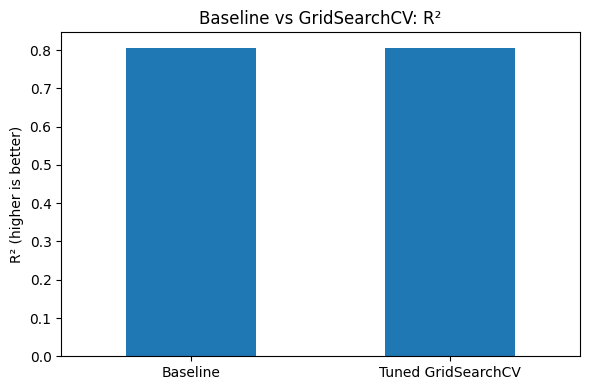

In [8]:
comparison[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 5))
plt.ylabel("Error (lower is better)")
plt.title("Baseline vs GridSearchCV: MAE and RMSE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison["R2"].plot(kind="bar", figsize=(6, 4))
plt.ylabel("R² (higher is better)")
plt.title("Baseline vs GridSearchCV: R²")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Interpretation and conclusion

Compare the printed metrics:
- Lower **MAE** and **RMSE** mean smaller prediction errors.
- Higher **R²** means the model explains more variation in the target.
- Report the measured percentage reduction in MAE/RMSE and the change in R². Do not claim improvement if the test results do not show it.

GridSearchCV selected the parameters using cross-validation on the training set. The test set was held out for the final comparison.